# Quesiton 1

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras.optimizers import Adam, SGD
from sklearn.model_selection import train_test_split

# Set random seed for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# CIFAR-10 class labels
class_names = [
    'airplane', 'automobile', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
]

# Load CIFAR-10 dataset
(X_train_full, y_train_full), (X_test, y_test) = tf.keras.datasets.cifar10.load_data()

# Combine all data to perform the required 70%-30% split across the full dataset
X_all = np.concatenate([X_train_full, X_test], axis=0).astype('float32') / 255.0
y_all = np.concatenate([y_train_full, y_test], axis=0).flatten()

# Split into 70% Training and 30% Validation
X_train, X_val, y_train, y_val = train_test_split(
    X_all, y_all,
    test_size=0.30,
    random_state=42,
    stratify=y_all
)

# Flatten images for fully connected neural network (32 * 32 * 3 = 3072)
X_train_flat = X_train.reshape(-1, 3072)
X_val_flat = X_val.reshape(-1, 3072)

print(f"Full dataset shape:       {X_all.shape}")
print(f"Training set (70%):       {X_train_flat.shape}, labels: {y_train.shape}")
print(f"Validation set (30%):     {X_val_flat.shape}, labels: {y_val.shape}")

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2065s 12us/step
Full dataset shape:       (60000, 32, 32, 3)
Training set (70%):       (42000, 3072), labels: (42000,)
Validation set (30%):     (18000, 3072), labels: (18000,)


Part I. Visualize the Data by Plotting Single Image of Each Catagory

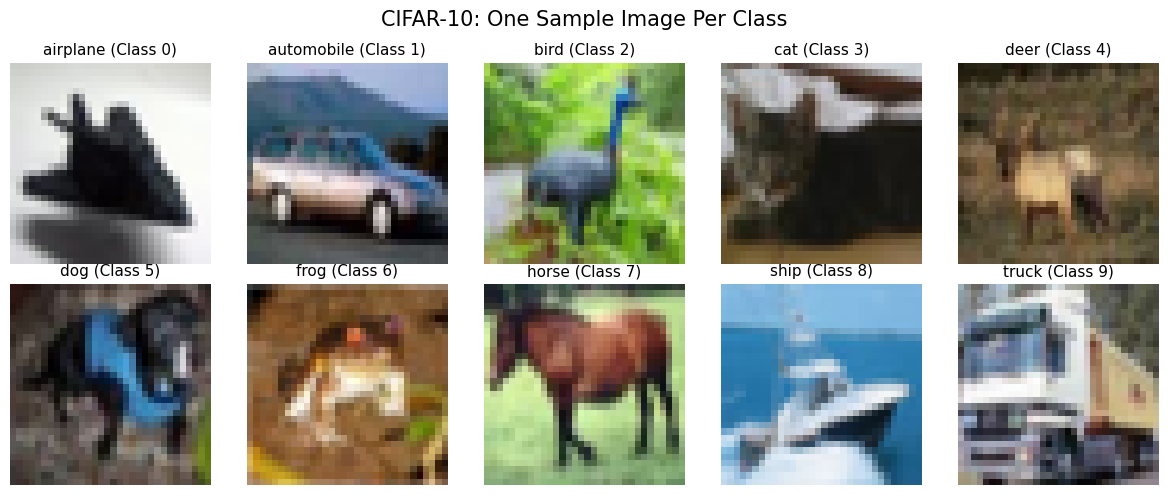

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
fig.suptitle("CIFAR-10: One Sample Image Per Class", fontsize=15, y=0.98)

for class_idx in range(10):
    # Find the index of the first occurrence of this class in the dataset
    idx = np.where(y_all == class_idx)[0][0]

    row, col = divmod(class_idx, 5)
    ax = axes[row, col]
    ax.imshow(X_all[idx])
    ax.set_title(f"{class_names[class_idx]} (Class {class_idx})", fontsize=11)
    ax.axis('off')

plt.tight_layout()
plt.show()

Part II. Demonstrate the Tuning of the Hyperparameters

In [4]:
def create_fcnn_model(hidden_units=[256, 128], learning_rate=0.001, optimizer_name='adam'):
    """Constructs a fully connected classification neural network."""
    model = Sequential()
    # First hidden layer with 3072 inputs
    model.add(Dense(hidden_units[0], input_shape=(3072,), activation='relu'))

    # Additional hidden layers
    for units in hidden_units[1:]:
        model.add(Dense(units, activation='relu'))

    # Output layer: 10 logits for 10 classes
    model.add(Dense(10, activation='softmax'))

    # Optimizer selection
    if optimizer_name.lower() == 'adam':
        opt = Adam(learning_rate=learning_rate)
    else:
        opt = SGD(learning_rate=learning_rate, momentum=0.9)

    model.compile(
        optimizer=opt,
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

# Define hyperparameter search grid
param_grid = {
    'hidden_units': [[256, 128], [512, 256, 128]],
    'learning_rate': [0.001, 0.0005],
    'optimizer_name': ['adam', 'sgd']
}

# Grid-search screening
X_tune_train = X_train_flat[:10000]
y_tune_train = y_train[:10000]
X_tune_val = X_val_flat[:2000]
y_tune_val = y_val[:2000]

grid_results = []
print("Starting Grid-Search across hyperparameter combinations...\n")
print(f"{'Hidden Units':<18} | {'LR':<7} | {'Opt':<5} | {'Val Accuracy':<12}")
print("-" * 50)

for hu in param_grid['hidden_units']:
    for lr in param_grid['learning_rate']:
        for opt_name in param_grid['optimizer_name']:
            model = create_fcnn_model(hidden_units=hu, learning_rate=lr, optimizer_name=opt_name)

            # Train candidate model for 10 epochs
            model.fit(
                X_tune_train, y_tune_train,
                validation_data=(X_tune_val, y_tune_val),
                epochs=10,
                batch_size=128,
                verbose=0
            )

            _, val_acc = model.evaluate(X_tune_val, y_tune_val, verbose=0)
            grid_results.append({
                'hidden_units': hu,
                'learning_rate': lr,
                'optimizer_name': opt_name,
                'val_accuracy': val_acc
            })
            print(f"{str(hu):<18} | {lr:<7} | {opt_name:<5} | {val_acc:.4f}")

# Select best combination
best_params = max(grid_results, key=lambda x: x['val_accuracy'])
print("\n" + "=" * 50)
print(f"Optimal Hyperparameters: {best_params}")
print("=" * 50)

Starting Grid-Search across hyperparameter combinations...

Hidden Units       | LR      | Opt   | Val Accuracy
--------------------------------------------------


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


[256, 128]         | 0.001   | adam  | 0.4075
[256, 128]         | 0.001   | sgd   | 0.3675
[256, 128]         | 0.0005  | adam  | 0.3905
[256, 128]         | 0.0005  | sgd   | 0.3460
[512, 256, 128]    | 0.001   | adam  | 0.4020
[512, 256, 128]    | 0.001   | sgd   | 0.3675
[512, 256, 128]    | 0.0005  | adam  | 0.4065
[512, 256, 128]    | 0.0005  | sgd   | 0.3490

Optimal Hyperparameters: {'hidden_units': [256, 128], 'learning_rate': 0.001, 'optimizer_name': 'adam', 'val_accuracy': 0.4074999988079071}


In [5]:
# Build tuned model with best hyperparameters found
tuned_model = create_fcnn_model(
    hidden_units=best_params['hidden_units'],
    learning_rate=best_params['learning_rate'],
    optimizer_name=best_params['optimizer_name']
)

tuned_model.summary()

# Train on the complete 70% training set (42,000 samples) and evaluate on 30% val set (18,000 samples)
EPOCHS = 35
BATCH_SIZE = 128

history = tuned_model.fit(
    X_train_flat, y_train,
    validation_data=(X_val_flat, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=1
)

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_28 (Dense)                │ (None, 256)            │       786,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_29 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_30 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 820,874 (3.13 MB)

 Trainable params: 820,874 (3.13 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/35
329/329 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.3170 - loss: 1.9030 - val_accuracy: 0.3671 - val_loss: 1.7799
Epoch 2/35
329/329 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.3944 - loss: 1.7015 - val_accuracy: 0.4159 - val_loss: 1.6651
Epoch 3/35
329/329 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4243 - loss: 1.6217 - val_accuracy: 0.4288 - val_loss: 1.6235
Epoch 4/35
329/329 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4421 - loss: 1.5658 - val_accuracy: 0.4439 - val_loss: 1.5775
Epoch 5/35
329/329 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4548 - loss: 1.5286 - val_accuracy: 0.4493 - val_loss: 1.5522
Epoch 6/35
329/329 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4671 - loss: 1.4961 - val_accuracy: 0.4585 - val_loss: 1.5382
Epoch 7/35
329/329 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4792 - loss: 1.4662 - val_accuracy: 0.4526 - val_loss: 1.5460
Epoch 8/35
329/329 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4891 - loss: 1.4414 - val_accuracy: 0.

Part III. & IV. Calculate and Plot The Training and Validation Losses and Accuracies

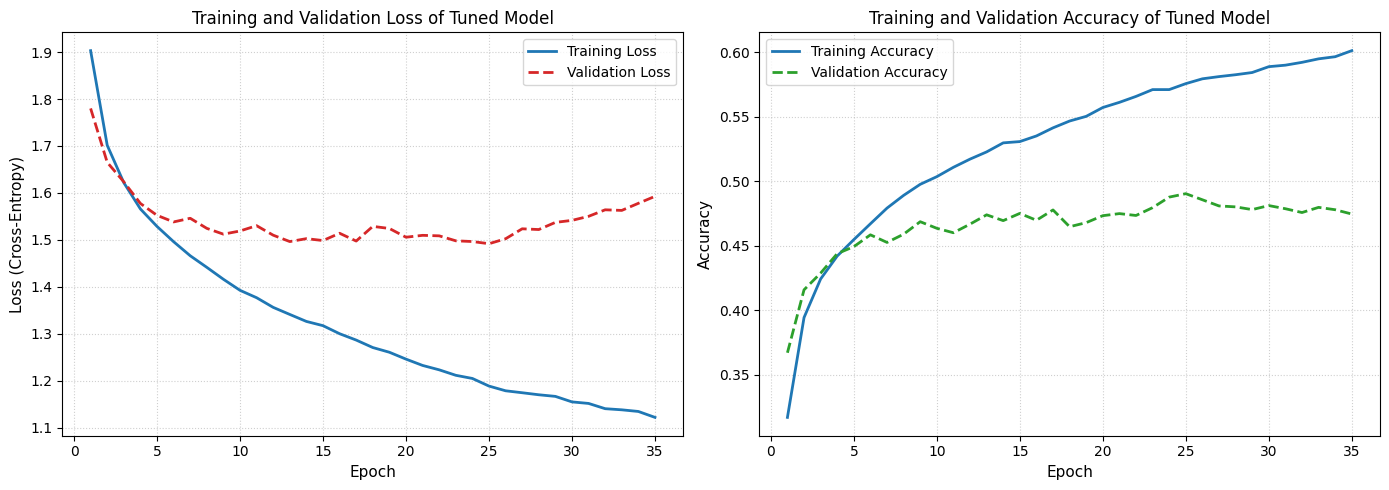

Final Validation Loss:     1.5926
Final Validation Accuracy: 47.46%


In [6]:
# Extract metrics history
train_loss = history.history['loss']
val_loss = history.history['val_loss']
train_acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
epochs_range = range(1, EPOCHS + 1)

# Plot loss and accuracy curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=100)

# III.) Training and Validation Losses
axes[0].plot(epochs_range, train_loss, label='Training Loss', color='#1f77b4', linewidth=2)
axes[0].plot(epochs_range, val_loss, label='Validation Loss', color='#d62728', linestyle='--', linewidth=2)
axes[0].set_title('Training and Validation Loss of Tuned Model', fontsize=12)
axes[0].set_xlabel('Epoch', fontsize=11)
axes[0].set_ylabel('Loss (Cross-Entropy)', fontsize=11)
axes[0].grid(True, linestyle=':', alpha=0.6)
axes[0].legend()

# IV.) Training and Validation Accuracies
axes[1].plot(epochs_range, train_acc, label='Training Accuracy', color='#1f77b4', linewidth=2)
axes[1].plot(epochs_range, val_acc, label='Validation Accuracy', color='#2ca02c', linestyle='--', linewidth=2)
axes[1].set_title('Training and Validation Accuracy of Tuned Model', fontsize=12)
axes[1].set_xlabel('Epoch', fontsize=11)
axes[1].set_ylabel('Accuracy', fontsize=11)
axes[1].grid(True, linestyle=':', alpha=0.6)
axes[1].legend()

plt.tight_layout()
plt.show()

# Final calculated validation performance
final_val_loss, final_val_acc = tuned_model.evaluate(X_val_flat, y_val, verbose=0)
print(f"Final Validation Loss:     {final_val_loss:.4f}")
print(f"Final Validation Accuracy: {final_val_acc * 100:.2f}%")

# Question 2

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# Load NASA Airfoil Self-Noise dataset directly from UCI repository
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00291/airfoil_self_noise.dat"
column_names = [
    'Frequency',
    'Angle_of_Attack',
    'Chord_Length',
    'Free_Stream_Velocity',
    'Suction_Side_Displacement_Thickness',
    'Sound_Pressure_Level'
]

df = pd.read_csv(url, sep='\t', names=column_names)

print("Dataset Shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

Dataset Shape: (1503, 6)

First 5 rows:


,Frequency,Angle_of_Attack,Chord_Length,Free_Stream_Velocity,Suction_Side_Displacement_Thickness,Sound_Pressure_Level
0,800,0.0,0.3048,71.3,0.002663,126.201
1,1000,0.0,0.3048,71.3,0.002663,125.201
2,1250,0.0,0.3048,71.3,0.002663,125.951
3,1600,0.0,0.3048,71.3,0.002663,127.591
4,2000,0.0,0.3048,71.3,0.002663,127.461


Part I. Visualize the Dataset

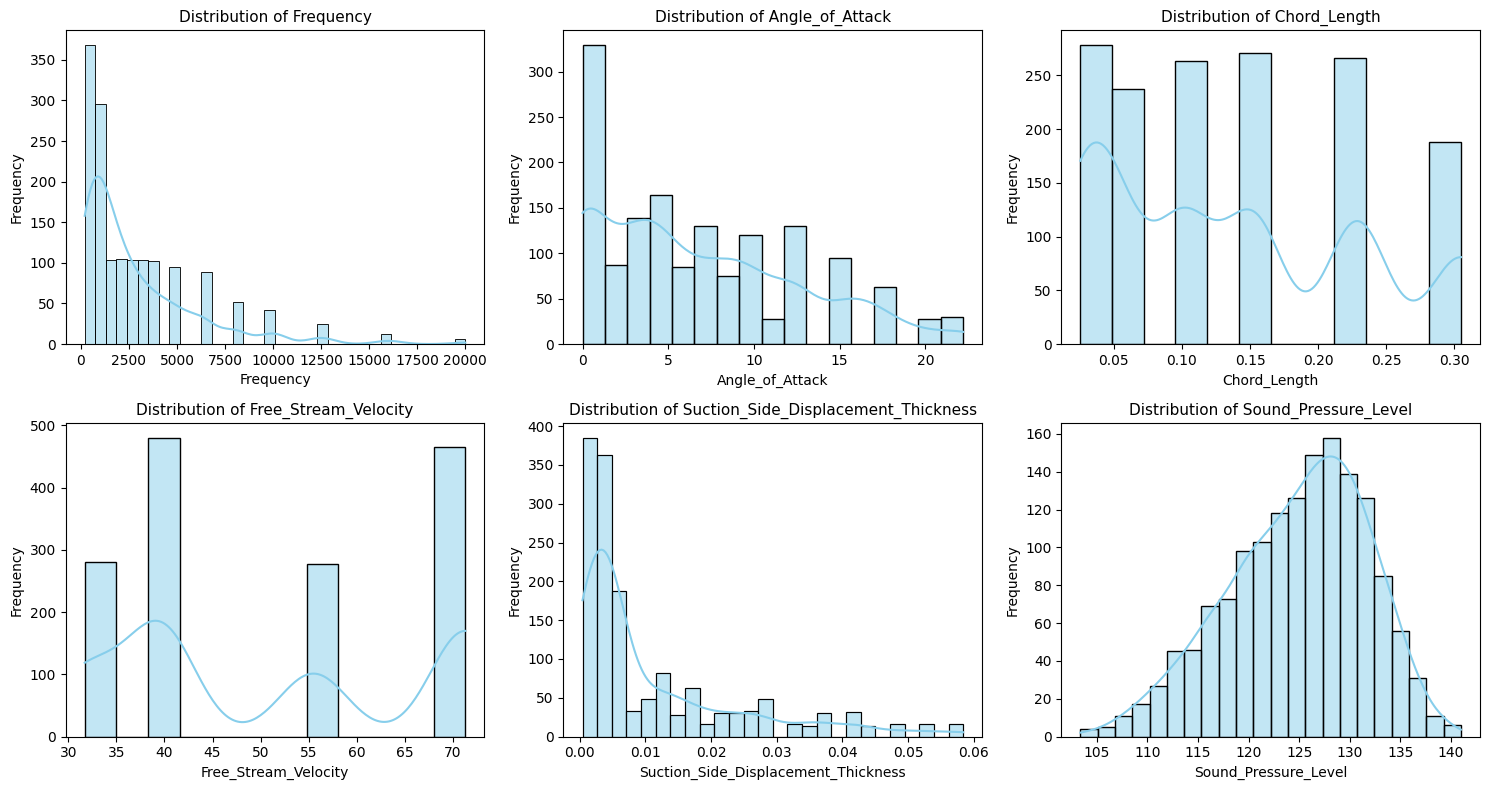

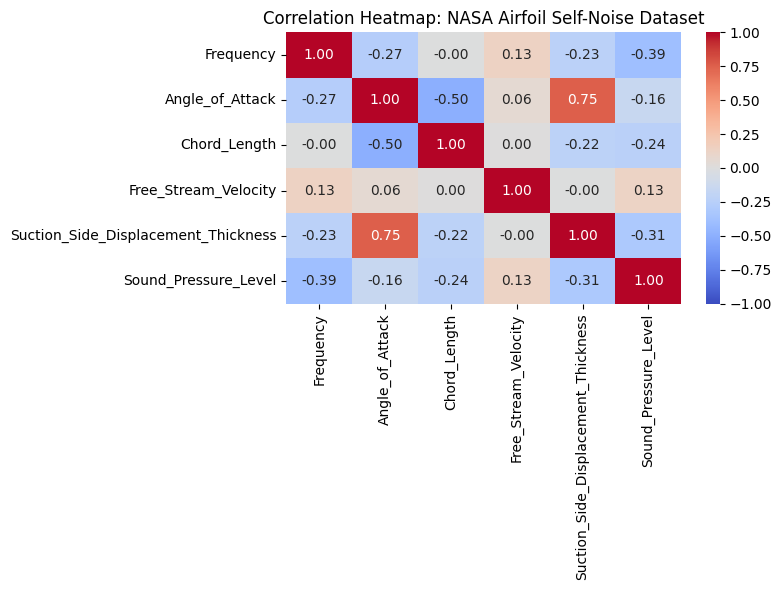

In [8]:
plt.figure(figsize=(15, 8), dpi=100)

# Histograms of all 6 attributes
for idx, col in enumerate(df.columns):
    plt.subplot(2, 3, idx + 1)
    sns.histplot(df[col], kde=True, color='skyblue', edgecolor='black')
    plt.title(f"Distribution of {col}", fontsize=11)
    plt.xlabel(col, fontsize=10)
    plt.ylabel("Frequency", fontsize=10)

plt.tight_layout()
plt.show()

# Correlation Heatmap
plt.figure(figsize=(8, 6), dpi=100)
corr_matrix = df.corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Heatmap: NASA Airfoil Self-Noise Dataset", fontsize=12)
plt.tight_layout()
plt.show()

In [9]:
# Separate features and target
X = df.drop(columns=['Sound_Pressure_Level']).values
y = df['Sound_Pressure_Level'].values

# Split data: 70% Training, 30% Validation
X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42
)

# Standardize input features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

print(f"Training set:   {X_train_scaled.shape}, target: {y_train.shape}")
print(f"Validation set: {X_val_scaled.shape}, target: {y_val.shape}")

Training set:   (1052, 5), target: (1052,)
Validation set: (451, 5), target: (451,)


Part II. Construct Fully Connected Neural Network

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_31 (Dense)                │ (None, 64)             │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_32 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_33 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_34 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,657 (26.00 KB)

 Trainable params: 6,657 (26.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/150
33/33 ━━━━━━━━━━━━━━━━━━━━ 4s 62ms/step - loss: 9224.7217 - mae: 87.5924 - val_loss: 1986.3606 - val_mae: 35.5102
Epoch 2/150
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 764.0332 - mae: 21.7515 - val_loss: 390.1974 - val_mae: 15.9303
Epoch 3/150
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 323.9437 - mae: 14.3327 - val_loss: 260.4317 - val_mae: 13.0266
Epoch 4/150
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 234.1356 - mae: 12.2149 - val_loss: 194.8544 - val_mae: 11.2794
Epoch 5/150
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 172.5806 - mae: 10.4924 - val_loss: 148.1526 - val_mae: 9.8527
Epoch 6/150
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 127.7741 - mae: 9.0379 - val_loss: 113.1058 - val_mae: 8.6207
Epoch 7/150
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 94.6967 - mae: 7.7821 - val_loss: 86.1461 - val_mae: 7.5200
Epoch 8/150
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 72.2840 - mae: 6.7944 - val_loss: 67.8272 - val_mae: 6.6611
Epoch 9/150
33/33 ━━━━

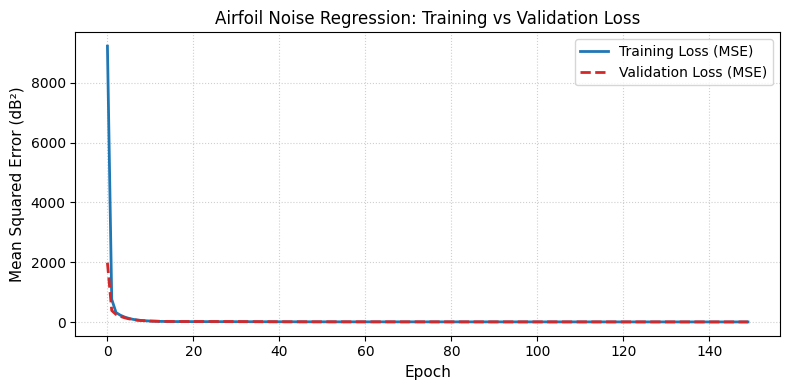

In [10]:
model = Sequential([
    Dense(64, activation='relu', input_shape=(5,)),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(1, activation='linear')  # Single neuron for estimating continuous sound pressure level (dB)
])

# Compile model using MSE loss and Adam optimizer
model.compile(optimizer=Adam(learning_rate=0.005), loss='mse', metrics=['mae'])
model.summary()

# Train model over 150 epochs
history = model.fit(
    X_train_scaled, y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=150,
    batch_size=32,
    verbose=1
)

# Plot training and validation loss curves
plt.figure(figsize=(8, 4), dpi=100)
plt.plot(history.history['loss'], label='Training Loss (MSE)', color='#1f77b4', lw=2)
plt.plot(history.history['val_loss'], label='Validation Loss (MSE)', color='#d62728', linestyle='--', lw=2)
plt.title('Airfoil Noise Regression: Training vs Validation Loss', fontsize=12)
plt.xlabel('Epoch', fontsize=11)
plt.ylabel('Mean Squared Error (dB²)', fontsize=11)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

Part III. Calculate Coefficient of Determination

15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step
Coefficient of Determination (R²): 0.7806
Validation Mean Squared Error (MSE):  10.3588 dB²
Validation Mean Absolute Error (MAE): 2.4205 dB


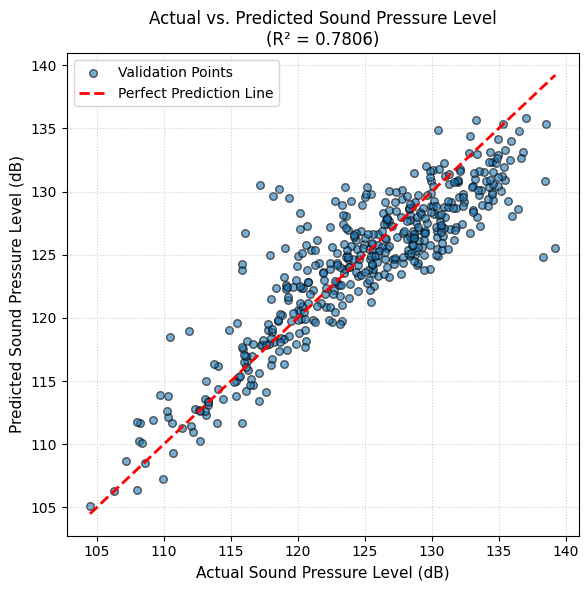

In [11]:
y_val_pred = model.predict(X_val_scaled).flatten()

# Calculate R^2 score
r2 = r2_score(y_val, y_val_pred)
mse = mean_squared_error(y_val, y_val_pred)
mae = mean_absolute_error(y_val, y_val_pred)

print("=" * 45)
print(f"Coefficient of Determination (R²): {r2:.4f}")
print(f"Validation Mean Squared Error (MSE):  {mse:.4f} dB²")
print(f"Validation Mean Absolute Error (MAE): {mae:.4f} dB")
print("=" * 45)

# Parity plot: Actual vs Predicted Sound Pressure Level
plt.figure(figsize=(6, 6), dpi=100)
plt.scatter(y_val, y_val_pred, alpha=0.6, color='#1f77b4', edgecolor='k', s=30, label='Validation Points')
plt.plot([y_val.min(), y_val.max()], [y_val.min(), y_val.max()], 'r--', lw=2, label='Perfect Prediction Line')
plt.title(f'Actual vs. Predicted Sound Pressure Level\n(R² = {r2:.4f})', fontsize=12)
plt.xlabel('Actual Sound Pressure Level (dB)', fontsize=11)
plt.ylabel('Predicted Sound Pressure Level (dB)', fontsize=11)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()